# Preprocessing and Exploratory Data Analysis

**Rayyan Agha Alnimer**


In [ ]:
# Locate the project data (works from the repo root or notebooks folder)
from pathlib import Path

project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "data" / "raw" / "medication_adherence.xlsx").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not find data/raw/medication_adherence.xlsx. Open this notebook from the project directory.")


In [ ]:
# Load the original dataset
import pandas as pd

file_path = project_root / "data" / "raw" / "medication_adherence.xlsx"
df = pd.read_excel(file_path)

print(df.shape)
df.head()


In [ ]:
# Inspect the dataset

df.info() # column types + (potential) missing data
df.describe() # stats
counts = df['ADHERENCE'].value_counts() # check class balance

# Check the percentage split in adherence vs. non-adherence
pct = df['ADHERENCE'].value_counts(normalize=True) * 100

# Print the count and the percentage of split
print("Counts:\n", counts)
print("\nPercentages:\n", pct)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24084 entries, 0 to 24083
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ADHERENCE               24084 non-null  object 
 1   AGE                     24084 non-null  int64  
 2   ANNUALCONTRIBUTION      24084 non-null  float64
 3   ANNUALCLAIMAMOUNT       24084 non-null  float64
 4   UNITSTOTAL              24084 non-null  float64
 5   GENDER_M                24084 non-null  bool   
 6   SCHEMETYPE_MEDIUM       24084 non-null  bool   
 7   SCHEMETYPE_PREMIUM      24084 non-null  bool   
 8   DIAGNOSIS_HYPERTENSION  24084 non-null  bool   
 9   COVERTYPE_STANDARD      24084 non-null  bool   
 10  NO_COMORBIDITY          24084 non-null  bool   
 11  NO_COMPLICATION         24084 non-null  bool   
dtypes: bool(7), float64(3), int64(1), object(1)
memory usage: 1.1+ MB
Counts:
 ADHERENCE
NON-ADHERENT    14415
ADHERENT         9669
Name: count, dt

##### Note: the number of non-adherents is approximately 60%, whereas the number of adherents is ~40%. This validates existing research findings the project is based on.

# *EDA and Preprocessing the Data:*

##1. **'AGE'**: this will be one of the cleaner numeric features. We can begin through analyzing the data

=== AGE ===
count    24084.000000
mean        56.579762
std         14.479047
min         16.000000
25%         46.000000
50%         56.000000
75%         66.000000
max        103.000000
Name: AGE, dtype: float64

Skewness: 0.16


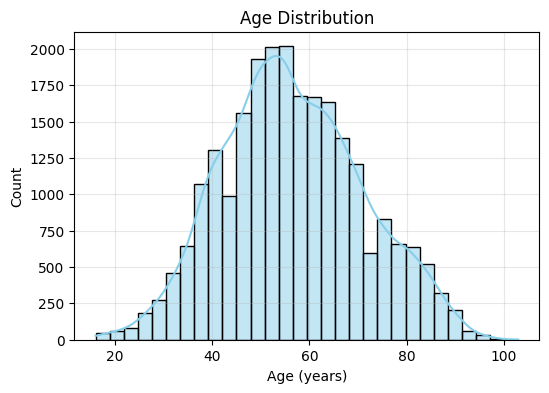

In [ ]:
# Begin by analyzing the age column and understanding the distribution

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Print out the mean, std, quartiles, and the skeweness of data
print("=== AGE ===")
print(df['AGE'].describe())
print("\nSkewness:", df['AGE'].skew().round(2))

# Histogram plotting the age frequences and the overall distribution of age
plt.figure(figsize=(6,4))
sns.histplot(df['AGE'], bins=30, kde=True, color='skyblue', edgecolor='black')
plt.title("Age Distribution")
plt.xlabel("Age (years)")
plt.ylabel("Count")
plt.grid(alpha=0.3)
plt.show()


The data follows what is expected from a dataset about hypertension and diabetes:
- The mean age recorded is between 56-57, which is to be expected as the risk diabetes and hypertension usually increases with age.
- The skeweness = 0.16 (nearly symmetrical; anything between -0.5 and +0.5 is typically considered approx. normal).
- The histogram looks almost like a bell-shaped curve, centred around the late 50s.
- The range (16-103) is realistic and bounded, preserving shape without distortion.

The best preprocessing strategy here will probably be Z-score standardization (StandardScaler), which will keep the mean = 0 and std = 1, preserving shape w/o distortion.


##2. **'ANNUALCONTRIBUTION' (in ZWL):** it seems that the values represent discrete payment tiers (like low, medium, high insurance contribution levels).

=== ANNUALCONTRIBUTION ===
count    2.408400e+04
mean     5.993621e+06
std      2.291566e+06
min      2.117640e+05
25%      2.718696e+06
50%      6.889900e+06
75%      6.889900e+06
max      1.177079e+07
Name: ANNUALCONTRIBUTION, dtype: float64

Unique values:  10

Skewness:  -0.67


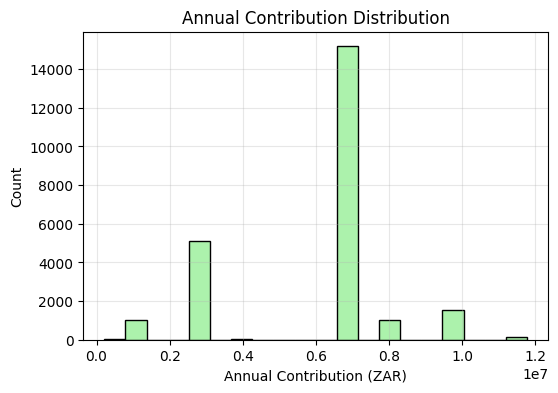


Sorted unique contribution values:
[np.float64(211764.0), np.float64(690384.0), np.float64(808284.0), np.float64(2718696.0), np.float64(3864159.0), np.float64(6740121.0), np.float64(6889900.0), np.float64(8232361.5), np.float64(9724602.0), np.float64(11770788.0)]


In [ ]:
# We begin by analyzing the distribution of the column

import matplotlib.pyplot as plt
import seaborn as sns

# print out the mean, std, quartiles, unique values, and skeweness
print("=== ANNUALCONTRIBUTION ===")
print(df['ANNUALCONTRIBUTION'].describe())
print("\nUnique values: ", df['ANNUALCONTRIBUTION'].nunique())
print("\nSkewness: ", df['ANNUALCONTRIBUTION'].skew().round(2))

# plot the distribution of 'ANNUALCONTRIBUTION'
plt.figure(figsize=(6,4))
sns.histplot(df['ANNUALCONTRIBUTION'], bins=20, color='lightgreen', edgecolor='black')
plt.title("Annual Contribution Distribution")
plt.xlabel("Annual Contribution (ZAR)")
plt.ylabel("Count")
plt.grid(alpha=0.3)
plt.show()

# Also print sorted unique values to visualize tiers
print("\nSorted unique contribution values:")
print(sorted(df['ANNUALCONTRIBUTION'].unique()))

In [ ]:
# Extract the frequency counts for ANNUALCONTRIBUTION

# compute counts, percentages, and sorted order
vc = (
    df['ANNUALCONTRIBUTION'].
    value_counts().
    rename_axis('ANNUALCONTRIBUTION').
    reset_index(name='count')
)

# add a percentage column for easier interpretation
total = len(df)
vc['percent'] = (vc['count'] / total * 100).round(2)

# sort from highest frequency first, then smallest contribution
vc_sorted = vc.sort_values(by=['count', 'ANNUALCONTRIBUTION'], ascending=[False, True])

# preview the top 100 — this covers all 10 unique contribution tiers
top100 = vc_sorted.head(100)

# show number of unique contribution amounts
unique_count = df['ANNUALCONTRIBUTION'].nunique()

print(f"\nUnique contribution tiers: {unique_count}\n")
print(top100)



Unique contribution tiers: 10

   ANNUALCONTRIBUTION  count  percent
0           6889900.0  13083    54.32
1           2718696.0   5103    21.19
2           6740121.0   2098     8.71
3           9724602.0   1536     6.38
4            808284.0   1028     4.27
5           8232361.5   1017     4.22
6          11770788.0    159     0.66
7           3864159.0     45     0.19
8            690384.0     14     0.06
9            211764.0      1     0.00


As expected, the contributions follow discrete numerical values, which in this case were found to be 10. We can then apply ordinal encoding to this column for a better representation of the recorded data.

In [ ]:
# Create ordinal encoding for 'ANNUALCONTRIBUTION

# sort unique contribution amounts from lowest to highest
unique_contributions = sorted(df['ANNUALCONTRIBUTION'].unique())

# create mapping: lowest = 1, next = 2, ...
ordinal_map = {value: idx + 1 for idx, value in enumerate(unique_contributions)}

# print to verify mapping
print("Ordinal mapping for ANNUALCONTRIBUTION:\n")
for value, rank in ordinal_map.items():
    print(f"{value:,.2f}  →  {rank}")

# apply mapping to a new column
df['ANNUALCONTRIBUTION_ORD'] = df['ANNUALCONTRIBUTION'].map(ordinal_map)

# quick check
print("\nUnique ordinal levels: ", sorted(df['ANNUALCONTRIBUTION_ORD'].unique()))
df[['ANNUALCONTRIBUTION', 'ANNUALCONTRIBUTION_ORD']].head(10)

Ordinal mapping for ANNUALCONTRIBUTION:

211,764.00  →  1
690,384.00  →  2
808,284.00  →  3
2,718,696.00  →  4
3,864,159.00  →  5
6,740,121.00  →  6
6,889,900.00  →  7
8,232,361.50  →  8
9,724,602.00  →  9
11,770,788.00  →  10

Unique ordinal levels:  [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


,ANNUALCONTRIBUTION,ANNUALCONTRIBUTION_ORD
0,690384.0,2
1,2718696.0,4
2,808284.0,3
3,808284.0,3
4,808284.0,3
5,808284.0,3
6,2718696.0,4
7,808284.0,3
8,808284.0,3
9,808284.0,3


This shows that an ordinal encoded column of 'ANNUALCONTRIBUTION' was successfully created and applied.

##3. **'ANNUALCLAIMAMOUNT' (in ZWL):** this column represents the total value of all medical claims a patient submitted to the insurer (Cimas Medical Aid Society) within one year (consultations, medication, lab tests, hospital visits). This will probably have a very heavy right-skew because a few patients generate huge medical bills while most claim small amounts.

=== ANNUAL CLAIM AMOUNT ===
count    2.408400e+04
mean     6.579390e+05
std      6.127169e+07
min      9.900000e-01
25%      1.230677e+04
50%      4.043974e+04
75%      1.020879e+05
max      9.401312e+09
Name: ANNUALCLAIMAMOUNT, dtype: float64

Skewness: 150.39


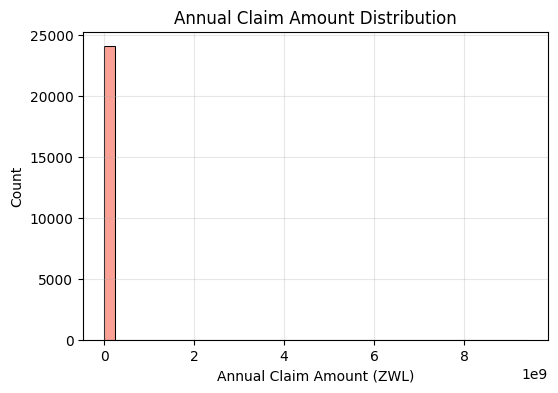

In [ ]:
# Again, start by analyzing the data and its distribution

# ============================================================
# ANNUAL CLAIM AMOUNT analysis
# ============================================================
print("=== ANNUAL CLAIM AMOUNT ===")
print(df['ANNUALCLAIMAMOUNT'].describe())
print("\nSkewness:", df['ANNUALCLAIMAMOUNT'].skew().round(2))

plt.figure(figsize=(6,4))
sns.histplot(df['ANNUALCLAIMAMOUNT'], bins=40, color='salmon', edgecolor='black')
plt.title("Annual Claim Amount Distribution")
plt.xlabel("Annual Claim Amount (ZWL)")
plt.ylabel("Count")
plt.grid(alpha=0.3)
plt.show()


It seems that the data has a very large skeweness to it, which corresponds to why it is not represented properly in the histogram. This is due to the patients submitting relatively modest claims, with a tiny fraction of claims that incur astronomical costs.

To make this data usable, we need to compress the dynamic range of data so that the samaller values aren't effectively invisible. A log-transform (`np.log1p`) would be appropriate here.

Therefore, we will scale (before global scaling) this column using log(1+x), with the +1 making the data transformation robust to zeros while shrinking outliers dramatically.

Skeweness before:  150.39
Skeweness after:  -0.5


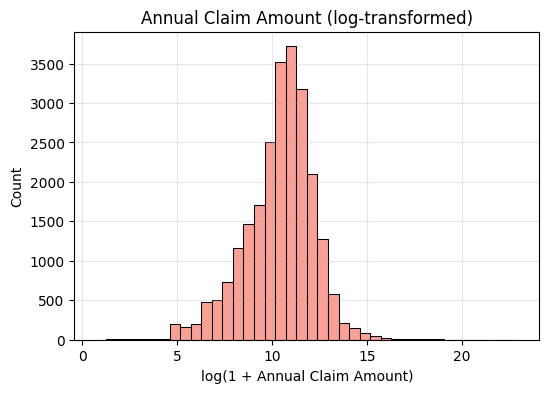

In [ ]:
# log1p transform to reduce skew
claim_log = np.log1p(df['ANNUALCLAIMAMOUNT'])

print("Skeweness before: ", round(df['ANNUALCLAIMAMOUNT'].skew(), 2))
print("Skeweness after: ", round(claim_log.skew(), 2))

plt.figure(figsize=(6,4))
sns.histplot(claim_log, bins=40, color='salmon', edgecolor='black')
plt.title("Annual Claim Amount (log-transformed)")
plt.xlabel("log(1 + Annual Claim Amount)")
plt.ylabel("Count")
plt.grid(alpha=0.3)
plt.show()

With a skeweness = -0.5 after applying a log transform, the distribution is now fairly symmetrical. The histogram now looks balanced around its mean.

##4. **'UNITSTOTAL':** the total number of medication units supplied or claimed for a patient over one year, as recorded in the pharmacy and claims data of Cimas Medical Aid Society.
- High values here means the patient consistently filled their prescriptions throughout the year (strong adherence, possibly multiple chronic conditions).
- Low values indicate few refills or missed medication periods, which are signs of potential non-adherence. However, values can vary depending on the type of medication (e.g., someone on insulin injections might use fewer total units than someone taking daily tablets).

Because of this aggregation across diff. medicine types, the raw numbers tend to be highly right-skewed (many patients consume modest amounts, while a few have very large totals).

=== UNITSTOTAL ===
count    2.408400e+04
mean     2.862657e+03
std      1.722682e+05
min      1.000000e+00
25%      1.200000e+02
50%      3.440000e+02
75%      7.200000e+02
max      2.129064e+07
Name: UNITSTOTAL, dtype: float64

Skewness: 102.82


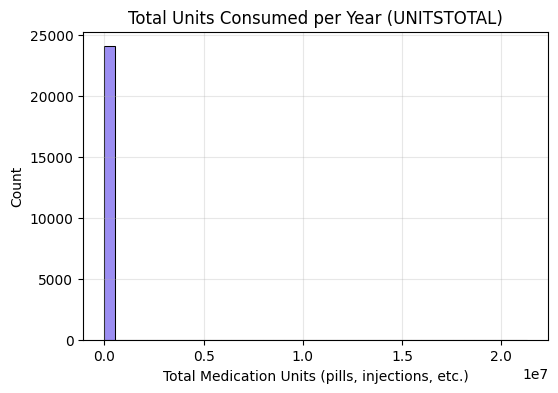

In [ ]:
# Again, analyzing

print("=== UNITSTOTAL ===")
print(df['UNITSTOTAL'].describe())
print("\nSkewness:", df['UNITSTOTAL'].skew().round(2))

plt.figure(figsize=(6,4))
sns.histplot(df['UNITSTOTAL'], bins=40, color='mediumslateblue', edgecolor='black')
plt.title("Total Units Consumed per Year (UNITSTOTAL)")
plt.xlabel("Total Medication Units (pills, injections, etc.)")
plt.ylabel("Count")
plt.grid(alpha=0.3)
plt.show()

Similar to 'ANNUALCLAIMAMOUNT', there is large skeweness that disrupts the distribution. This is to be expected as most patients receive modest prescriptions, while a tiny number consume extreme totals (multi-condition or long-term treatments). We can use the same recipe of log transform here.

Skewness before: 102.82
Skewness after : -0.66


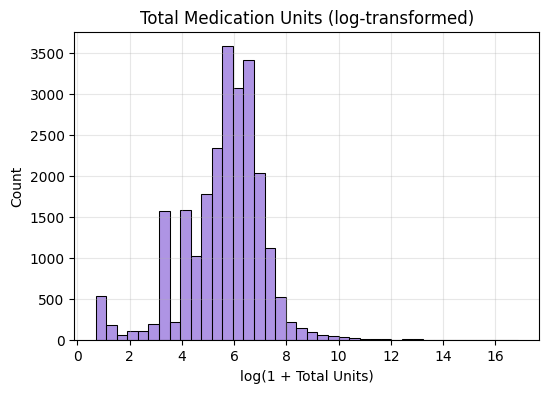

In [ ]:
# log1p transform to handle right skew
units_log = np.log1p(df['UNITSTOTAL'])

print("Skewness before:", round(df['UNITSTOTAL'].skew(), 2))
print("Skewness after :", round(units_log.skew(), 2))

plt.figure(figsize=(6,4))
sns.histplot(units_log, bins=40, color='mediumpurple', edgecolor='black')
plt.title("Total Medication Units (log-transformed)")
plt.xlabel("log(1 + Total Units)")
plt.ylabel("Count")
plt.grid(alpha=0.3)
plt.show()

The skeweness has been reduced to -0.66, which keeps it in that approx. symmetrical range b/w -1 and 1, which is acceptable normality.

###This concludes the numerical columns, which have been reviewed and scaled to ensure proper skeweness and distribution. Now, we head on to the boolean categorical features, where we will analyze the columns and preprocess if needed before global preprocessing is applied.

In [ ]:
# Boolean categorical features analysis

bool_cols = [
    'GENDER_M',
    'SCHEMETYPE_MEDIUM',
    'SCHEMETYPE_PREMIUM',
    'DIAGNOSIS_HYPERTENSION',
    'COVERTYPE_STANDARD',
    'NO_COMORBIDITY',
    'NO_COMPLICATION'
]

for col in bool_cols:
    print(f"=== {col} ===")
    print(df[col].value_counts(dropna=False))
    print(f"Percentage of True: {df[col].mean()*100:.2f}%\n")

=== GENDER_M ===
GENDER_M
True     13071
False    11013
Name: count, dtype: int64
Percentage of True: 54.27%

=== SCHEMETYPE_MEDIUM ===
SCHEMETYPE_MEDIUM
False    18936
True      5148
Name: count, dtype: int64
Percentage of True: 21.38%

=== SCHEMETYPE_PREMIUM ===
SCHEMETYPE_PREMIUM
True     17893
False     6191
Name: count, dtype: int64
Percentage of True: 74.29%

=== DIAGNOSIS_HYPERTENSION ===
DIAGNOSIS_HYPERTENSION
True     19279
False     4805
Name: count, dtype: int64
Percentage of True: 80.05%

=== COVERTYPE_STANDARD ===
COVERTYPE_STANDARD
True     19274
False     4810
Name: count, dtype: int64
Percentage of True: 80.03%

=== NO_COMORBIDITY ===
NO_COMORBIDITY
True     17108
False     6976
Name: count, dtype: int64
Percentage of True: 71.03%

=== NO_COMPLICATION ===
NO_COMPLICATION
True     21773
False     2311
Name: count, dtype: int64
Percentage of True: 90.40%



Here is what each column tells us about the dataset's structure:

**GENDER_M:**
- Well balanced; nearly equal gender split (can be kept as-is)

**SCHEMETYPE_MEDIUM:**
- Member is on the mid-tier insurance plan (moderate premium, moderate benefits).
- Minority of patients on medium-tier plan (Keep as-is w/o transformation)

**SCHEMETYPE_PREMIUM:**
- Member is on the high-tier insurance plan (high premium, broad coverage).
- Majority on premium plan; note some imbalance (Keep as-is since models can handle binary imbalance).

(Note: if both scheme types are `false`, the member is implicitly in the standard plan category, or the baseline group).

**DIAGNOSIS_HYPERTENSION:**
- Hypertension dominates dataset (as expected from study).

**COVERTYPE_STANDARD:**
- Refers to the benefit cover category rather than the plan type. Even with a scheme tier, members can select different coverage levels (e.g., standard impatient/outpatient limits vs. enhanced packages).
- `True` means the member is under standard coverage; `False` indicates extended or customized coverage. This distinguishes clinical differences from administrative plan structures.
- Similar dominance, typical of one insurance tier.

**NO_COMORBIDITY:**
- Flags patients who don't have secondary chronic conditons recorded in their medical history (e.g., asthma, cardiac disease).
- `True` indicates a single-conditon (either diabetes or hypertension *only*). `False` indicates multiple comorbid conditions.
- Most have no comorbidities, still usable.

**NO_COMPLICATION:**
- Indicates whether the patient had no recorded complications resulting from their chronic disease during the observation period.
- `True`: stable disease, no complications. `False`: at least one recorded complication.
- Very high; indicates data sparsity for "complicated" cases.
- Keep as-is (rare cases might help model learn extremes).


With this, we can apply the final preprocessing pipeline, applying global scaling to the dataset and moving on with different model training.

In [ ]:

# PREPROCESSING DATASET (CLEANED AND FIXED)


import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Copy to avoid altering the original dataset
df_scaled = df.copy()

# 1. Encode the target column: ADHERENCE → 0/1
# 0 = NON-ADHERENT, 1 = ADHERENT
df_scaled['ADHERENCE'] = df_scaled['ADHERENCE'].map({'NON-ADHERENT': 0, 'ADHERENT': 1}).astype(int)

# 2. AGE — z-score
scaler_age = StandardScaler()
df_scaled['AGE'] = scaler_age.fit_transform(df_scaled[['AGE']])

# 3. ANNUALCONTRIBUTION_ORD — z-score (after ordinal encoding)
scaler_contrib = StandardScaler()
df_scaled['ANNUALCONTRIBUTION_ORD'] = scaler_contrib.fit_transform(df_scaled[['ANNUALCONTRIBUTION_ORD']])

# 4. ANNUALCLAIMAMOUNT — log1p + z-score
df_scaled['ANNUALCLAIMAMOUNT'] = np.log1p(df_scaled['ANNUALCLAIMAMOUNT'])
scaler_claim = StandardScaler()
df_scaled['ANNUALCLAIMAMOUNT'] = scaler_claim.fit_transform(df_scaled[['ANNUALCLAIMAMOUNT']])

# 5. UNITSTOTAL — log1p + z-score
df_scaled['UNITSTOTAL'] = np.log1p(df_scaled['UNITSTOTAL'])
scaler_units = StandardScaler()
df_scaled['UNITSTOTAL'] = scaler_units.fit_transform(df_scaled[['UNITSTOTAL']])

# 6. Boolean categorical columns — convert to 0/1 integers
bool_cols = [
    'GENDER_M', 'SCHEMETYPE_MEDIUM', 'SCHEMETYPE_PREMIUM',
    'DIAGNOSIS_HYPERTENSION', 'COVERTYPE_STANDARD',
    'NO_COMORBIDITY', 'NO_COMPLICATION'
]
df_scaled[bool_cols] = df_scaled[bool_cols].astype(int)

# 7. Drop the raw ANNUALCONTRIBUTION column (keep ordinal version)
df_scaled = df_scaled.drop(columns=['ANNUALCONTRIBUTION'], errors='ignore')

# 8. Reorder columns for clarity
column_order = [
    'ADHERENCE', 'AGE', 'ANNUALCONTRIBUTION_ORD', 'ANNUALCLAIMAMOUNT', 'UNITSTOTAL',
    'GENDER_M', 'SCHEMETYPE_MEDIUM', 'SCHEMETYPE_PREMIUM',
    'DIAGNOSIS_HYPERTENSION', 'COVERTYPE_STANDARD',
    'NO_COMORBIDITY', 'NO_COMPLICATION'
]
df_scaled = df_scaled[column_order]

# 9. Verify transformation
print("Preprocessing complete + ADHERENCE encoded as 0/1.")
print("\nUnique ADHERENCE values:", df_scaled['ADHERENCE'].unique())

# Show full dataset
df_scaled



Preprocessing complete + ADHERENCE encoded as 0/1.

Unique ADHERENCE values: [0 1]


,ADHERENCE,AGE,ANNUALCONTRIBUTION_ORD,ANNUALCLAIMAMOUNT,UNITSTOTAL,GENDER_M,SCHEMETYPE_MEDIUM,SCHEMETYPE_PREMIUM,DIAGNOSIS_HYPERTENSION,COVERTYPE_STANDARD,NO_COMORBIDITY,NO_COMPLICATION
0,0,-2.250178,-2.684938,-0.631035,-0.957200,0,0,0,0,1,1,1
1,0,-0.247243,-1.432984,1.238985,1.067979,1,1,0,0,1,1,1
2,0,-0.730710,-2.058961,0.479037,0.527898,1,0,0,0,1,0,1
3,0,1.341293,-2.058961,0.999916,0.746014,1,0,0,0,1,0,1
4,1,0.857825,-2.058961,0.706264,0.646074,0,0,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
24079,0,-0.454443,1.696901,-1.232941,-1.396608,1,0,1,1,0,1,1
24080,0,0.995959,1.696901,-1.062549,-1.396608,0,0,1,1,0,0,1
24081,0,-0.109109,0.444947,-1.173253,-1.396608,1,0,1,1,1,1,1
24082,1,-0.937910,0.444947,-4.840273,-1.396608,0,0,1,1,1,1,1


#####**Note:** A Standard Scaler was chosen because it centers each feature around a mean of 0 and a standard deviation of 1, preserving the shape of the data and making it suitable for algorithms that assume normally distributed inputs (like logistic regression and SVMs). In contrast, Min–Max scaling compresses all values into a fixed 0–1 range, which can distort the influence of outliers and skewed variables, especially in this dataset, where claim and unit totals vary across several orders of magnitude.

Now that the updated dataset has been preprocessed and retains the same structure as the initial dataset, we can export it into a csv file to begin our modelling.

In [ ]:
# Export the processed dataset for model training
output_path = project_root / "data" / "processed" / "preprocessed_dataset.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
df_scaled.to_csv(output_path, index=False)
print(f"Processed dataset saved to: {output_path}")
